# stFormer Benchmarking

- Creator: Sebastian Birk (sb75@sanger.ac.uk)
- Date of Creation: 03.12.2024
- Date of Last Modification: 03.12.2024 (by Sebastian Birk; sb75@sanger.ac.uk)

- The stFormer source code only works for deconvolved spot resolution data.
- Install stFormer as described here https://github.com/csh3/stFormer/tree/main (important: install the correct Python version ```conda install python=3.11.5 -c conda-forge```.
    - To install flash-attn, first install torch via ```pip install torch==2.2.2+cu121 --index-url https://download.pytorch.org/whl/cu121``` and then run ```module load cuda-12.1.1```.
- Download the pretrained model weights from https://github.com/csh3/stFormer/blob/main/pretraining/download.txt.

## 1. Setup

### 1.1 Load Libraries 

In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import sys
sys.path.append("../../utils")

In [14]:
import os
from typing import Dict

import anndata as ad
import pandas as pd
import scanpy as sc
import torch
from stformer import logger
from stformer.tokenizer import GeneVocab
from stformer.tokenizer import tokenize_and_pad_batch
from sklearn.metrics.cluster import adjusted_rand_score, normalized_mutual_info_score
from torch.utils.data import Dataset, DataLoader
from torch import nn

from analysis_utils import *

### 1.2 Configure Paths

In [18]:
st_data_folder_path = '/lustre/scratch126/cellgen/team361/DATASETS'
st_data_silver_folder_path = f'{st_data_folder_path}/silver'
artifacts_folder_path = '/lustre/scratch126/cellgen/team361/sb75/terra-reproducibility/artifacts/'
benchmarking_artifacts_folder_path = f'{artifacts_folder_path}/benchmarking'
stformer_folder_path = '/lustre/scratch126/cellgen/team361/sb75/stFormer/'

In [24]:
sys.path.append(f'{stformer_folder_path}/tasks/') # to import scfoundation

### 1.3 Define Config

In [5]:
dataset_name = 'xhs1000-39b_1p'
batches = ['batch11', 'batch19', 'batch32']
batch_key = 'sample'
niche_key = 'niche_type'
latent_cluster_key = 'predicted_niche'
latent_leiden_resolution = 0.6

In [30]:
DEVICE = 'cuda:0'

### 1.4 Run Notebook Setup

In [6]:
sc.settings.figdir = f'{benchmarking_artifacts_folder_path}/figures'

In [7]:
os.makedirs(f'{benchmarking_artifacts_folder_path}/figures', exist_ok=True)
os.makedirs(f'{benchmarking_artifacts_folder_path}/metrics', exist_ok=True)

### 1.5 Define Functions

In [12]:
class SlideData():
    def __init__(self, data_path, slide, vocab, pad_value, pad_token):
        self.data_path = data_path
        self.slide = slide
        self.vocab = vocab
        self.pad_value = pad_value
        self.pad_token = pad_token
        self.load_data()
    
    def load_data(self):
        adata = sc.read_h5ad(f'{self.data_path}/{self.slide}_Visium_deconv.h5ad')

        scfoundation_gene_df = pd.read_csv(f'{tokenizer_dir}/scfoundation_gene_df.csv')
        scfoundation_gene_df.set_index('gene_ids', inplace=True)
        total_gene_num = adata.shape[1]
        adata = adata[:, adata.var_names.isin(scfoundation_gene_df.index)]
        adata.var['gene_name'] = scfoundation_gene_df.loc[adata.var_names, 'gene_symbols'].values
        seleted_gene_num = adata.shape[1]
        genes = adata.var["gene_name"].tolist()
        gene_ids = np.array(self.vocab(genes), dtype=int)

        logger.info(
            f"match {seleted_gene_num}/{total_gene_num} genes "
            f"in vocabulary of size 19264."
        )

        ligand_database = pd.read_csv(tokenizer_dir+'ligand_database.csv', header=0, index_col=0)
        ligand_symbol = ligand_database[ligand_database.sum(1)>1].index.values
        ligand_ids = self.vocab(ligand_symbol.tolist())
        adata = adata[(adata[:,adata.var['gene_name'].isin(ligand_symbol)].X.sum(1)>0).A.T[0],:]
            
        celltype_proportion = adata.obsm['q05_cell_abundance_w_sf']
        celltype_proportion.rename(columns=lambda x: x[23:], inplace=True)
        celltype_proportion = celltype_proportion.div(celltype_proportion.sum(axis=1), axis=0)
        celltype_proportion[celltype_proportion < 0.05] = 0
        celltype_proportion = celltype_proportion.div(celltype_proportion.sum(axis=1), axis=0)

        for celltype in adata.layers.keys():
            adata.X = adata.layers[celltype]
            sc.pp.normalize_total(adata, target_sum=1e4)
            sc.pp.log1p(adata)
            adata.uns.pop('log1p')
            adata.layers[celltype] = adata.X

        self.adata = adata
        self.celltype_proportion = celltype_proportion
        self.gene_ids = gene_ids
        self.ligand_ids = ligand_ids
    
    def get_niche_samples(self):
        samples_expression = []
        samples_ctprop = []
        celltypes_labels = []
        for i in range(self.adata.shape[0]):
            ct_prop = self.celltype_proportion.iloc[i][self.celltype_proportion.iloc[i]>0]

            niche_counts = np.concatenate([self.adata.layers[ct][i].A for ct in ct_prop.index])
            niche_counts[:,~np.isin(self.gene_ids, self.ligand_ids)] = 0

            niche_ctprop = ct_prop.values

            for ct in ct_prop.index:
                counts = self.adata.layers[ct][i].A
                samples_expression.append(np.concatenate([counts, niche_counts],axis=0))
                samples_ctprop.append(niche_ctprop)
                celltypes_labels.append(ct)

        celltype_ids = pd.Series(celltypes_labels).astype("category").cat.codes.values

        self.expression = samples_expression
        self.ctprop = samples_ctprop
        self.celltypes = celltypes_labels
        self.celltype_ids = celltype_ids

    def tokenize_data(self):
        max_seq_len = np.max(np.count_nonzero(self.adata.X.A, axis=1))+2
        max_niche_cell_num = (self.celltype_proportion>0).sum(1).max()
        self.max_seq_len = max_seq_len
        self.max_niche_cell_num = max_niche_cell_num

        self.tokenized_data = tokenize_and_pad_batch(
            self.expression,
            self.ctprop,
            self.gene_ids,
            max_len = max_seq_len,
            max_niche_cell_num = max_niche_cell_num,
            vocab = self.vocab,
            pad_token = self.pad_token,
            pad_value = self.pad_value,
            append_cls = False,  # append <cls> token at the beginning
            include_zero_gene = False,
        )
     
        logger.info(
            f"Number of samples: {self.tokenized_data['center_genes'].shape[0]}, "
            f"\n\t feature length of center cell: {self.tokenized_data['center_genes'].shape[1]}"
            f"\n\t feature length of niche cells: {self.tokenized_data['niche_genes'].shape[1]}"
        )

    def prepare_data(self):
        self.data_pt = {
            "center_gene_ids": self.tokenized_data["center_genes"],
            "input_center_values": self.tokenized_data["center_values"],
            "target_center_values": self.tokenized_data["center_values"],
            "niche_gene_ids": self.tokenized_data["niche_genes"],
            "input_niche_values": self.tokenized_data["niche_values"],
            "niche_feature_lens": self.tokenized_data["niche_feature_lens"],
            "cross_attn_bias": self.tokenized_data["cross_attn_bias"],
        }
    
    def prepare_dataloader(self, batch_size):
        data_loader = DataLoader(
            dataset=SeqDataset(self.data_pt),
            batch_size=batch_size,
            shuffle=False,
            drop_last=False,
            num_workers=min(len(os.sched_getaffinity(0)), batch_size // 2),
            pin_memory=True,
        )
        return data_loader

class SeqDataset(Dataset):
    def __init__(self, data: Dict[str, torch.Tensor]):
        self.data = data

    def __len__(self):
        return self.data["center_gene_ids"].shape[0]

    def __getitem__(self, idx):
        return {k: v[idx] for k, v in self.data.items()}

In [15]:
def evaluate(model: nn.Module, loader: DataLoader) -> float:
    """
    Evaluate the model on the evaluation data.
    """
    model.eval()
    cell_embeddings = []

    with torch.no_grad():
        for batch_data in tqdm(loader):
            niche_feature_lens = batch_data["niche_feature_lens"].to(device)
            if niche_feature_lens.size(0)<7:
                continue
            center_gene_ids = batch_data["center_gene_ids"].to(device)
            input_center_values = batch_data["input_center_values"].to(device)
            niche_gene_ids = batch_data["niche_gene_ids"].to(device)
            input_niche_values = batch_data["input_niche_values"].to(device)
            cross_attn_bias = batch_data["cross_attn_bias"].to(device)

            encoder_src_key_padding_mask = niche_gene_ids.eq(vocab[pad_token])
            decoder_src_key_padding_mask = center_gene_ids.eq(vocab[pad_token])

            with torch.cuda.amp.autocast(enabled=amp):
                output_dict = model(
                        niche_gene_ids,
                        input_niche_values,
                        encoder_src_key_padding_mask,
                        center_gene_ids,
                        input_center_values,
                        decoder_src_key_padding_mask,
                        cross_attn_bias,
                    )
                cell_embeddings.append(output_dict['cell_emb'].to('cpu'))
    
    return(torch.cat(cell_embeddings))

## 2. Data

In [16]:
# Load hold out skin samples and concatenate in one adata object
adata_list = []

for subdir, _, files in os.walk(f'{st_data_silver_folder_path}/{dataset_name}'):
    for file_idx, file in enumerate(files):
        if file.endswith('.h5ad') & any(batch in file for batch in batches):
            file_path = os.path.join(subdir, file)
            adata = sc.read_h5ad(file_path)
            adata_list.append(adata)

adata = ad.concat(adata_list, join='outer', index_unique=None)

/lustre/scratch126/cellgen/team361/sb75/conda/envs/stformer/lib/python3.11/site-packages/anndata/_core/anndata.py:1906: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")
/lustre/scratch126/cellgen/team361/sb75/conda/envs/stformer/lib/python3.11/site-packages/anndata/_core/anndata.py:1906: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


/lustre/scratch126/cellgen/team361/sb75/conda/envs/stformer/lib/python3.11/site-packages/scanpy/plotting/_utils.py:431: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  adata.uns[value_to_plot + '_colors'] = colors_list
/lustre/scratch126/cellgen/team361/sb75/conda/envs/stformer/lib/python3.11/site-packages/scanpy/plotting/_tools/scatterplots.py:1251: FutureWarning: The default value of 'ignore' for the `na_action` parameter in pandas.Categorical.map is deprecated and will be changed to 'None' in a future version. Please set na_action to the desired value to avoid seeing this warning
  color_vector = pd.Categorical(values.map(color_map))


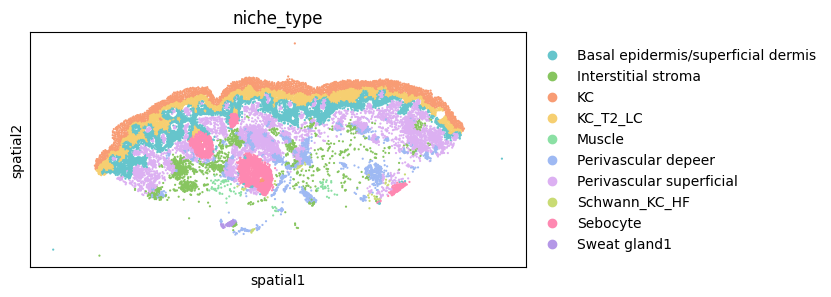

/lustre/scratch126/cellgen/team361/sb75/conda/envs/stformer/lib/python3.11/site-packages/scanpy/plotting/_utils.py:431: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  adata.uns[value_to_plot + '_colors'] = colors_list
/lustre/scratch126/cellgen/team361/sb75/conda/envs/stformer/lib/python3.11/site-packages/scanpy/plotting/_tools/scatterplots.py:1251: FutureWarning: The default value of 'ignore' for the `na_action` parameter in pandas.Categorical.map is deprecated and will be changed to 'None' in a future version. Please set na_action to the desired value to avoid seeing this warning
  color_vector = pd.Categorical(values.map(color_map))


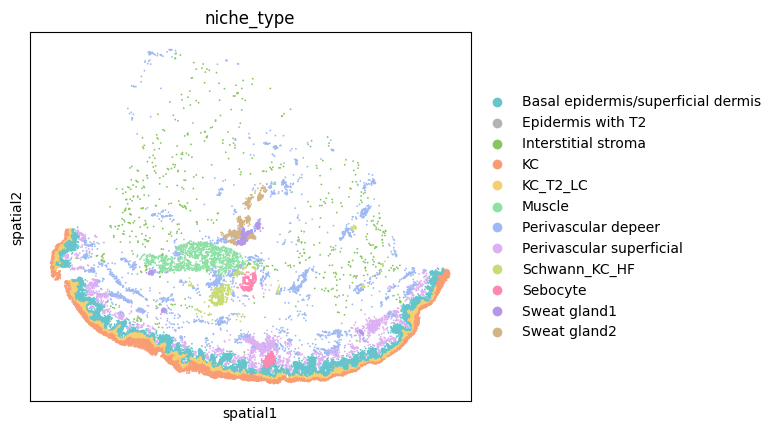

/lustre/scratch126/cellgen/team361/sb75/conda/envs/stformer/lib/python3.11/site-packages/scanpy/plotting/_utils.py:431: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  adata.uns[value_to_plot + '_colors'] = colors_list
/lustre/scratch126/cellgen/team361/sb75/conda/envs/stformer/lib/python3.11/site-packages/anndata/_core/anndata.py:1906: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")
/lustre/scratch126/cellgen/team361/sb75/conda/envs/stformer/lib/python3.11/site-packages/anndata/_core/anndata.py:1906: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")
/lustre/scratch126/cellgen/team361/sb75/conda/envs/stformer/lib/python3.11/site-packages/scanpy/plotting/_tools/scatterplots.py:1251: FutureWarning: The default value of 'ignore' for the `na_action` parameter in p

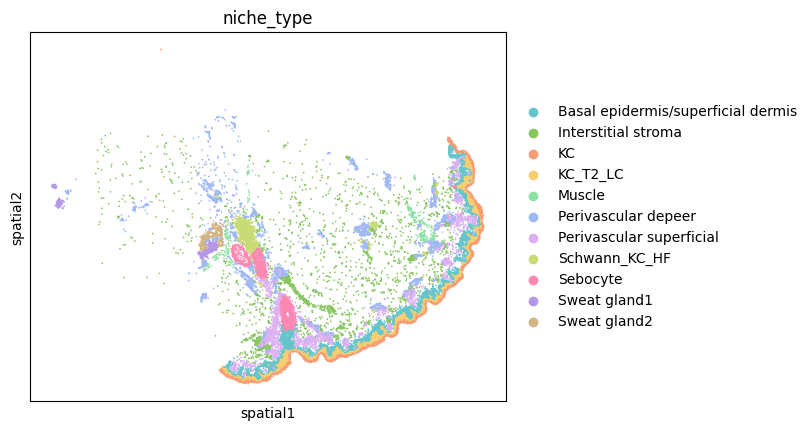

In [17]:
# Plot ground truth niches
spot_sizes = [20, 20, 20]
custom_palette_ground_truth = {niche: custom_palette[number] for niche, number in zip(
    adata.obs[niche_key].unique().tolist(), custom_palette)}

batch_ids = adata.obs[batch_key].unique().tolist()
for i, batch_id in enumerate(batch_ids):
    adata_batch = adata[adata.obs[batch_key] == batch_id]
    file_name = f'_ground_truth_niches_{batch_id}.svg'
    sc.pl.spatial(adata_batch,
                  color=niche_key,
                  palette=custom_palette_ground_truth,
                  spot_size=spot_sizes[i],
                  save=file_name)

## 3. Model

### 3.1 Zero-shot Niche Identification

In [26]:
model = torch.load(f'{stformer_folder_path}/pretraining/model.ckpt', map_location='cpu')

In [37]:
device = torch.device(DEVICE)

model = nn.DataParallel(model, device_ids = [0])
model.to(device)

DataParallel(
  (module): TransformerModel(
    (scfoundation_token_emb1): AutoDiscretizationEmbedding2(
      (mlp): Linear(in_features=1, out_features=100, bias=True)
      (mlp2): Linear(in_features=100, out_features=100, bias=True)
      (LeakyReLU): LeakyReLU(negative_slope=0.1)
      (Softmax): Softmax(dim=-1)
      (emb): Embedding(100, 768)
      (emb_mask): Embedding(1, 768)
      (emb_pad): Embedding(1, 768)
    )
    (scfoundation_token_emb2): AutoDiscretizationEmbedding2(
      (mlp): Linear(in_features=1, out_features=100, bias=True)
      (mlp2): Linear(in_features=100, out_features=100, bias=True)
      (LeakyReLU): LeakyReLU(negative_slope=0.1)
      (Softmax): Softmax(dim=-1)
      (emb): Embedding(100, 768)
      (emb_mask): Embedding(1, 768)
      (emb_pad): Embedding(1, 768)
    )
    (scfoundation_pos_emb1): Embedding(19267, 768)
    (scfoundation_pos_emb2): Embedding(19267, 768)
    (transformer_decoder): TransformerDecoder(
      (layers): ModuleList(
        (0-

In [40]:
pad_token = "<pad>"
pad_value = 103

tokenizer_dir = f'{stformer_folder_path}/stformer/tokenizer/'
vocab_file = tokenizer_dir + "scfoundation_gene_vocab.json"
vocab = GeneVocab.from_file(vocab_file)
vocab.append_token(pad_token)
vocab.set_default_index(vocab[pad_token])

In [ ]:
cell_embeddings = evaluate(model,data_loader)

In [ ]:
sc.pp.neighbors(adata,
                n_neighbors=15,
                use_rep='emb',
                method='rapids',
                key_added='emb')
sc.tl.umap(adata,
           neighbors_key='emb',
           method='rapids')
sc.tl.leiden(adata,
             neighbors_key='emb',
             key_added=latent_cluster_key,
             resolution=latent_leiden_resolution)

In [ ]:
# Plot predicted niches
spot_sizes = [20, 20, 20]

batch_ids = adata.obs[batch_key].unique().tolist()
for i, batch_id in enumerate(batch_ids):
    adata_batch = adata[adata.obs[batch_key] == batch_id]
    file_name = f'_cellplm_niches_{batch_id}.svg'
    sc.pl.spatial(adata_batch,
                  color=latent_cluster_key,
                  palette=custom_palette,
                  spot_size=spot_sizes[i],
                  save=file_name)

In [ ]:
# Compute metrics
labels = adata.obs[niche_key]
labels_pred = adata.obs[latent_cluster_key]

nmi = normalized_mutual_info_score(labels, labels_pred, average_method="arithmetic")
ari = adjusted_rand_score(labels, labels_pred)

print(f'NMI is {nmi}. ARI is {ari}.')

In [ ]:
metrics_df = pd.DataFrame({'Metric': ['NMI', 'ARI'], 'Value': [nmi, ari]})
metrics_df.to_csv(f'{benchmarking_artifacts_folder_path}/metrics/cellplm.csv', index=False)